![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Regression
*Data Science & Machine Learning - Week 4, Day 3*

**How to use this notebook**

Open the day with the slides **0. IntroAI**, then use **2. Regression & Curve Fitting** alongside sections 1 to 3.

The live lesson runs from section 1 to section 9. The Appendix is for practice.

The notebook reads data and images from the `files/` folder, so download or clone the whole `s-407` folder, not just this file.

## Table of Contents

- [1. What regression is for](#1.-What-regression-is-for)
- [2. The linear model](#2.-The-linear-model)
    - [2.1 Simple linear regression](#2.1-Simple-linear-regression)
    - [2.2 Interpolation vs. extrapolation](#2.2-Interpolation-vs.-extrapolation)
    - [2.3 Multiple regression](#2.3-Multiple-regression)
    - [2.4 Polynomial regression](#2.4-Polynomial-regression)
- [3. Ordinary Least Squares](#3.-Ordinary-Least-Squares)
- [4. Fitting a model with scikit-learn](#4.-Fitting-a-model-with-scikit-learn)
    - [4.1 Train and test split](#4.1-Train-and-test-split)
    - [4.2 Fit and predict](#4.2-Fit-and-predict)
- [5. Boston housing: predicting price from one feature](#5.-Boston-housing:-predicting-price-from-one-feature)
- [6. Evaluating a regression](#6.-Evaluating-a-regression)
- [7. Reading a regression summary with statsmodels](#7.-Reading-a-regression-summary-with-statsmodels)
- [8. Multiple linear regression](#8.-Multiple-linear-regression)
- [9. Regularization: Ridge and Lasso](#9.-Regularization:-Ridge-and-Lasso)
    - [9.1 L2 regularization: Ridge](#9.1-L2-regularization:-Ridge)
    - [9.2 L1 regularization: Lasso](#9.2-L1-regularization:-Lasso)
    - [9.3 Fitting both](#9.3-Fitting-both)
    - [9.4 Comparing the results](#9.4-Comparing-the-results)
    - [9.5 Summary: L1 vs L2](#9.5-Summary:-L1-vs-L2)
- [Appendix](#Appendix)
    - [A.1 Another estimator: least absolute errors](#A.1-Another-estimator:-least-absolute-errors)
    - [A.2 One feature at a time](#A.2-One-feature-at-a-time)
    - [A.3 Exploring relationships before modelling](#A.3-Exploring-relationships-before-modelling)

## 1. What regression is for

How do we make predictions about real-world quantities?

+  How does sales volume change with changes in price? How is it affected by weather?
+  How does the amount of a drug absorbed vary with body weight of patient? Does it depend on blood pressure?
+  How many customers can I expect today?
+  At what time should I go home to avoid the traffic jam?
+  What is the chance of rain for next two Mondays? What is the expected temperature?

<center><img src="files/images/crystal_ball_s.jpg"></center>

**Example:**
    
 
<center><img src="files/images/life-expectancy-vs-gdp-per-capita.png"></center>


You can find another interesting example [here](https://ourworldindata.org/grapher/life-expectancy-of-women-vs-life-expectancy-of-women?tab=chart&country=&region=World).

All these questions have a common structure: we are asking about one variable $\textbf{y}$ (*response*) that can be expressed as a combination of one or more (independent) variables $\textbf{x}_i$ (commonly called *covariates* or *predictors* or *regressors*).

The role of regression is to build a model (formula) to predict the response from the covariates.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rc('font', size=12)
plt.rc('figure', figsize=(12, 5))
sns.set_style("whitegrid")

seed = 12  # makes the random examples repeatable
np.random.seed(seed)

## 2. The linear model

**Notation:**

$x_i$ element of a vector, $\textbf{x}$ column vector, $\textbf{x'}$ (transpose of $\textbf{x}$) row vector, $X$ matrix.

The simplest model we can think of is the **linear model**, where the response $\textbf{y}$ depends linearly from the predictors $\textbf{x}_i$:

$$ \textbf{y}  =  a_1 \textbf{x}_1  + \dots + a_m \textbf{x}_{m} + \epsilon $$ 

The $a_i$ are termed *parameters* of the model or *coefficients* and $\epsilon$ is called *error term*, *disturbance term*, or *noise* (in contrast with the "signal" provided by the rest of the model). This variable captures all other factors which influence the dependent variable $ \textbf{y}$ other than the predictors $ \textbf{x}$. 

This equation can be rewritten in a more compact (matricial) form as

$$ \textbf{y}  = X \textbf{w} + \epsilon $$

where $$ \textbf{y} = \left( \begin{array}{c} y_1 \\ y_2 \\ \vdots \\ y_n \end{array} \right), 
 X = \left( \begin{array}{c} x_{11}  \dots x_{1m} \\ x_{21}  \dots x_{2m}\\ \vdots \\ x_{n1}  \dots x_{nm} \end{array} \right),  \textbf{w} = \left( \begin{array}{c} a_1 \\ a_2 \\ \vdots \\ a_m \end{array} \right) 
 \epsilon = \left( \begin{array}{c} \epsilon_1 \\ \epsilon_2 \\ \vdots \\ \epsilon_m \end{array} \right) $$
 
 **Linear regression** is the technique for creating linear models.
 
### 2.1 Simple linear regression

In the **simple** linear regression, with a single variable, we describe the relationship between the predictor and the response with a straight line. 

The model is:
$$ \textbf{y}  =  a_0+ a_1 \textbf{x}_1 + \epsilon$$

The parameter $a_0$ is called the *constant term* or the *intercept*.

In the matricial form we add a constant term by changing to the matrix: $(\textbf{1},X).$

**Example:**

Does the insurance price depend on the driving experience?

Given the following information, the monthly auto insurance prices ($\textbf{y}$) and driving experiences in years ($\textbf{x}_{1}$) of a set of n=8 subjects, we can build a linear model to answer this question.


<center><img src="files/images/data-insurance.png" width="500"></center>


<center><img src="files/images/price-insurance.png" width="500"></center>



We can also predict the monthly auto insurance price for a driver with 20 years of driving experience.

### 2.2 Interpolation vs. extrapolation

In practice, when we do prediction for some value of x we haven’t seen before, we need to be very careful. Predicting $y$ for a value of $x$ that is within the interval of points that we saw in the original data (the data that we fit our model with) is called **interpolation**. Predicting y for a value of x that’s outside the range of values we actually saw for x in the original data is called **extrapolation**.
For real datasets, even if a linear fit seems appropriate, we need to be extremely careful about extrapolation, which can often lead to false predictions!


<center><img src="files/images/extrapolation.png"  width="500"></center>

### 2.3 Multiple regression
In Ordinary Least Squares Regression with a single variable we described the relationship between the predictor and the response with a straight line. This case is called *simple* linear regression. 

The simple linear regression can be extended to a higher number of variables. Having m preditor variables, we'll fit an m-dimensional hyperplane to our m predictors.

$$ \textbf{y} = a_1 \textbf{x}_1 + \dots + a_m \textbf{x}_m = X \textbf{w} $$

### 2.4 Polynomial regression

Despite its name, linear regression can be used to fit non-linear functions. A linear regression model is linear in the model parameters, not necessarily in the predictors. If you add non-linear transformations of your predictors to the linear regression model, the model will be non-linear in the predictors.

$$ \textbf{y} = a_1 \phi(\textbf{x}_1) + \dots + a_m \phi(\textbf{x}_m) $$

This very popular non-linear regression technique is *Polynomial Regression*, a technique which models the relationship between the response and the predictors as an n-th order polynomial. The higher the order of the polynomial the more "wigglier" functions you can fit. 

We can represent a curved relationship between our variables by introducing **polynomial** terms, as for example, a cubic model:


$$y_i \approx a_0 + a_1 x_i + a_2 x_i^2 + a_3 x_i^3$$

Using higher order polynomial comes at a price: **computational complexity** and **overfitting**. Overfitting refers to a situation in which the model fits the idiosyncrasies of the training data and loses the ability to generalize from the seen to predict the unseen.

Example:

<center><img src="files/images/overfitting.png" width = '700'></center>

## 3. Ordinary Least Squares

Let's generate some data to illustrate simple linear regression.

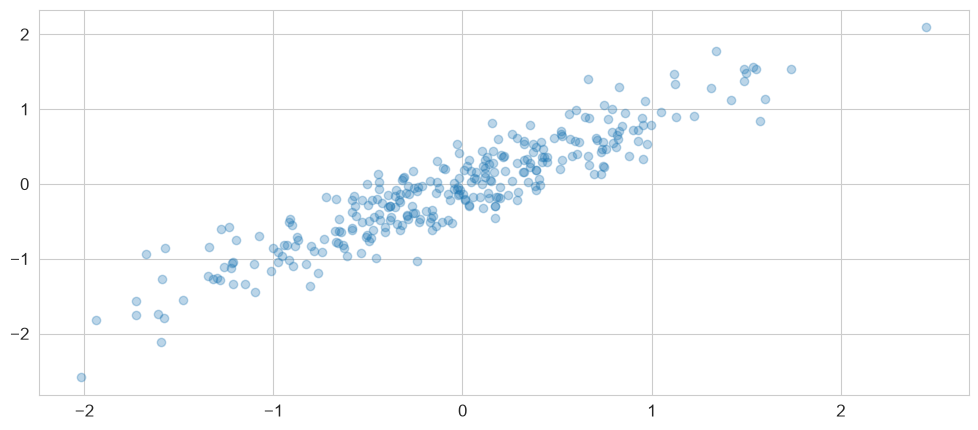

In [2]:
X1 = np.random.randn(300, 2)                  # random points from a normal distribution
A = np.array([[0.6, .4], [.4, 0.6]])          # transformation matrix that correlates them
X2 = np.dot(X1, A)

X = X2[:, 0]
y = X2[:, 1]

plt.plot(X, y, "o", alpha=0.3)
plt.show()

We can draw a linear model through the data:

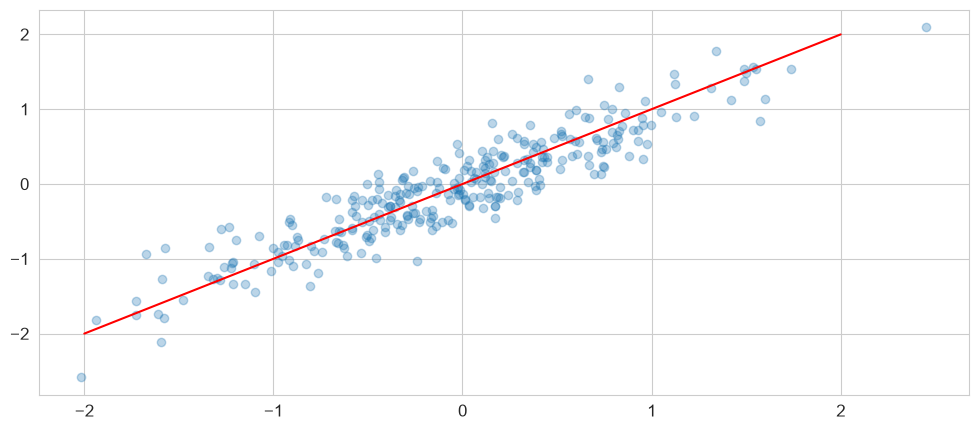

In [3]:
model = [0 + 1*x for x in np.arange(-2, 3)]   # y = x

plt.plot(X, y, "o", alpha=0.3)
plt.plot(np.arange(-2, 3), model, 'r')       # the red line gives the predictions of this model
plt.show()

But there are other linear models. Which one is best?

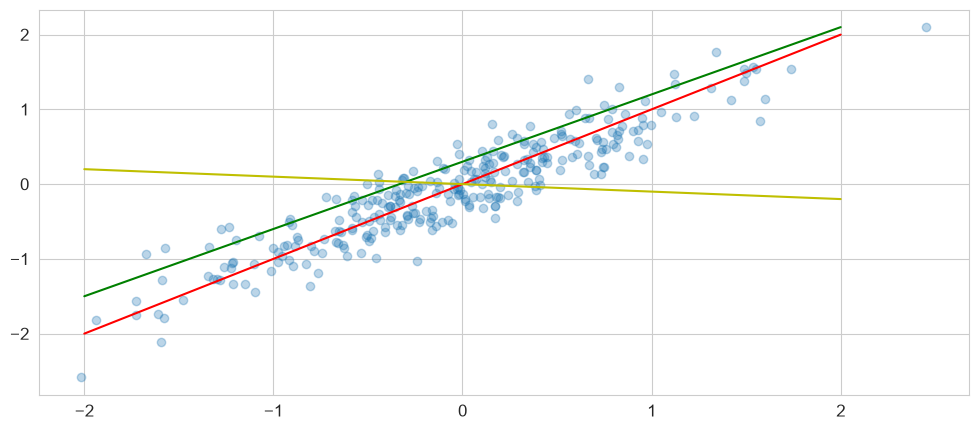

In [4]:
model1 = [0 + 1*x for x in np.arange(-2, 3)]       # y = x
model2 = [0.3 + 0.9*x for x in np.arange(-2, 3)]   # y = 0.3 + 0.9x
model3 = [0 - 0.1*x for x in np.arange(-2, 3)]     # y = -0.1x

plt.plot(X, y, "o", alpha=0.3)
plt.plot(np.arange(-2, 3), model1, 'r')
plt.plot(np.arange(-2, 3), model2, 'g')
plt.plot(np.arange(-2, 3), model3, 'y')
plt.show()

Consider the overdetermined system

$$\textbf{y} = a_0 + a_1 \textbf{x}$$

Ordinary Least Squares (OLS) is the simplest and most common **estimator** in which the two \(a\)'s are chosen to minimize the sum of squared distances between the predicted values and the actual values.

Given the set of samples \((\textbf{x}, \textbf{y})\), the objective is to minimize:

$$
||a_0 + a_1 \textbf{x} - \textbf{y} ||^2_2 = \sum_{j=1}^n (a_0 + a_1 x_j - y_j )^2,
$$

with respect to \(a_0, a_1\).

This expression is often called the **sum of squared errors of prediction (SSE)**.

**Demo:** https://phet.colorado.edu/sims/html/least-squares-regression/latest/least-squares-regression_all.html — play with this demo tool to understand what regression is doing

**Computing the OLS line with `scipy.optimize`**

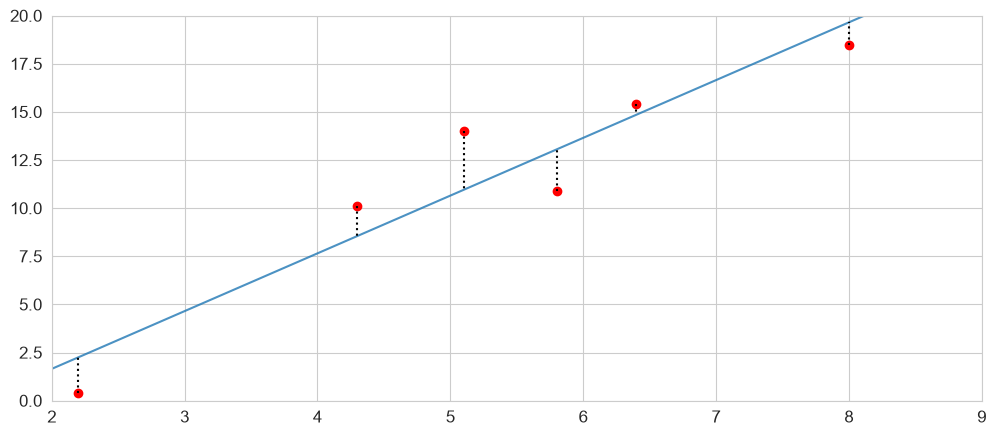

-4.350013603887088 3.0000002915386412


In [5]:
from scipy.optimize import fmin

x = np.array([2.2, 4.3, 5.1, 5.8, 6.4, 8.0])
y = np.array([0.4, 10.1, 14.0, 10.9, 15.4, 18.5])

# sum of squared errors for a line with intercept a[0] and slope a[1]
sse = lambda a, x, y: np.sum((a[0] + a[1]*x - y) ** 2)

a0, a1 = fmin(sse, [0, 1], args=(x, y), disp=False)   # [0, 1] is the starting guess

plt.plot(x, y, 'ro')
plt.plot([0, 10], [a0, a0 + a1*10], alpha=0.8)
for xi, yi in zip(x, y):
    plt.plot([xi]*2, [yi, a0 + a1*xi], "k:")   # the errors being minimised
plt.xlim(2, 9); plt.ylim(0, 20)
plt.show()
print(a0, a1)

The pointed black lines illustrate the vertical errors which are minimized.

**Note**: There are alternatives of errors-in-variables regression models as the **total least squares**.

**OLS is a popular approach for several reasons**

+ It is computationally cheap to calculate the coefficients. 
+ It is easier to interpret than more sophisticated models. In situations where the goal is understanding a simple model in detail, rather than estimating the response well, they can provide insight into what the model captures. 
+ Finally, in situations where there is a lot of noise, it may be hard to find the true functional form, so a constrained model can perform quite well compared to a complex model which is more affected by noise.

The resulting model is represented as follows:

$$\widehat{\textbf{y}} = \widehat{a}_0+\widehat{a}_1 \textbf{x}$$

Here the hats on the variables represent the fact that they are estimated from the data we have available.

## 4. Fitting a model with scikit-learn

### 4.1 Train and test split

One of the key aspects of supervised machine learning is model evaluation and validation. When you evaluate the predictive performance of your model, it’s essential that the process be unbiased. 

You can’t evaluate the predictive performance of a model with the same data you used for training. You need evaluate the model with fresh data that hasn’t been seen by the model before. You can accomplish that by splitting your dataset before you use it.

Using train_test_split() from the data science library scikit-learn, you can split your dataset into subsets that minimize the potential for bias in your evaluation and validation process.

(12, 1) (12,)


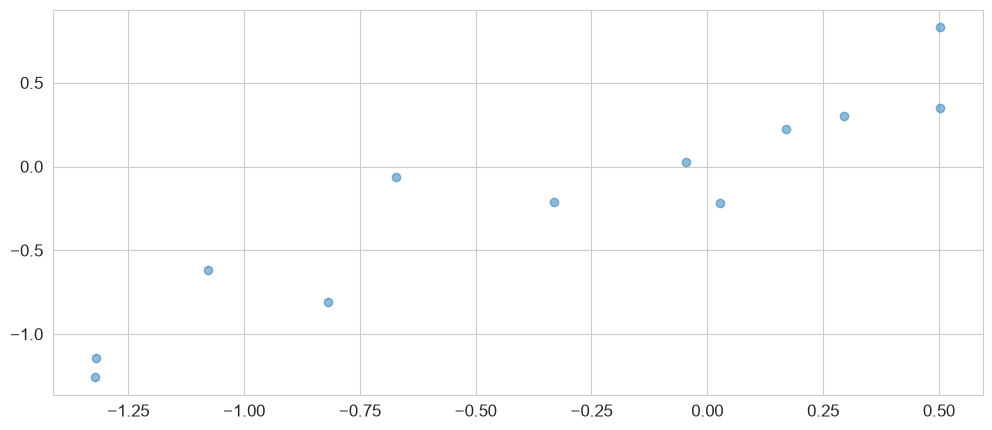

In [6]:
# a small dummy dataset
X1 = np.random.randn(12, 2)
A = np.array([[0.6, .4], [.4, 0.6]])
X2 = np.dot(X1, A)

X = X2[:, 0].reshape(-1, 1)   # scikit-learn wants X as a 2D array: one row per sample, one column per feature
y = X2[:, 1]

print(X.shape, y.shape)
plt.plot(X, y, "o", alpha=0.5)
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=seed)

print(X.shape, X_train.shape, X_test.shape)
print(y.shape, y_train.shape, y_test.shape)

(12, 1) (9, 1) (3, 1)
(12,) (9,) (3,)


### 4.2 Fit and predict

Let's make predictions using **Scikit-learn**. 

Scikit-learn is a library that provides a variety of both supervised and unsupervised machine learning techniques. Scikit-learn provides an object-oriented interface centered around the concept of an Estimator. 

The <code>Estimator.fit</code> method sets the state of the estimator based on the *training data*. Usually, the data is comprised of a two-dimensional numpy array $X$ of shape <code>(n_samples, n_predictors)</code> that holds the so-called *feature matrix* and a one-dimensional numpy array $\textbf{y}$ that holds the *responses*. Some estimators allow the user to control the fitting behavior. 
Estimators that can generate predictions provide a ``Estimator.predict`` method. 
In the case of regression, ``Estimator.predict`` will return the predicted regression values, $\widehat{\textbf{y}}$. 

During the fitting process, the state of the estimator is stored in the instance attributes that have a trailing underscore (``'_'``). For example, the coefficients of a ``LinearRegression`` estimator are stored in the attribute ``coef_``. Let's see a toy example:

In [8]:
from sklearn.linear_model import LinearRegression

lm = LinearRegression()      # create the estimator
lm.fit(X_train, y_train)     # learn the coefficients from the training data

print(lm.intercept_, lm.coef_)

0.12560891286047143 [0.90317819]


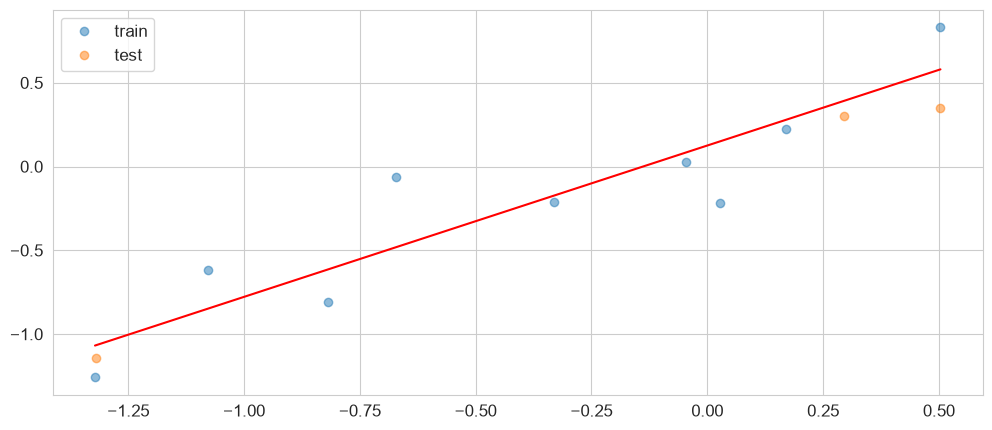

In [9]:
x_model = np.linspace(X.min(), X.max(), 50).reshape(-1, 1)

plt.plot(X_train, y_train, "o", alpha=0.5, label="train")
plt.plot(X_test, y_test, "o", alpha=0.5, label="test")
plt.plot(x_model, lm.predict(x_model), 'r')   # the red line gives the predictions of this model
plt.legend()
plt.show()

## 5. Boston housing: predicting price from one feature

The Boston housing data has 506 towns around Boston, with 12 attributes of each housing market and the median house price. We want to predict the price from the attributes.

| Column | Meaning |
| --- | --- |
| CRIM | per capita crime rate by town |
| ZN | proportion of residential land zoned for lots over 25,000 sq.ft. |
| INDUS | proportion of non-retail business acres per town |
| CHAS | Charles River dummy variable (1 if the tract bounds the river, 0 otherwise) |
| NOX | nitric oxides concentration (parts per 10 million) |
| RM | average number of rooms per dwelling |
| AGE | proportion of owner-occupied units built before 1940 |
| DIS | weighted distances to five Boston employment centres |
| RAD | index of accessibility to radial highways |
| TAX | full-value property-tax rate per $10,000 |
| PTRATIO | pupil-teacher ratio by town |
| LSTAT | % lower status of the population |
| MEDV | median value of owner-occupied homes in $1000s — **the target** |

The raw file has one more column, `B`, built from the proportion of Black residents in each town. It encodes a racist assumption, and it is the reason scikit-learn removed this dataset from its library. We drop it as soon as we load the data.

In [10]:
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
df_boston = pd.read_csv('files/housing.csv', header=None, sep=r"\s+", names=column_names)
df_boston = df_boston.drop(columns='B')

df_boston.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,5.33,36.2


In [11]:
df_boston['MEDV'].mean()

np.float64(22.532806324110677)

We start by predicting the **median house value** from a single attribute: **LSTAT**, the percentage of lower-status population.

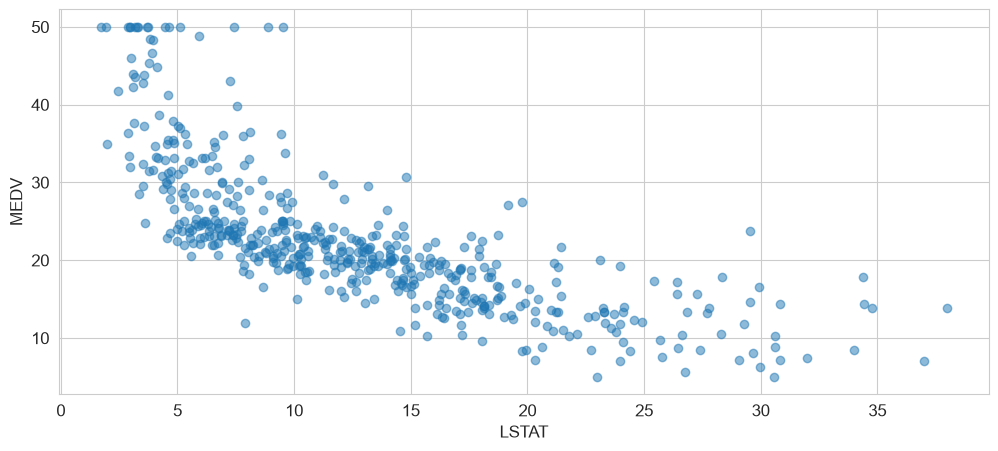

In [12]:
X = df_boston.LSTAT.values.reshape(-1, 1)
y = df_boston.MEDV.values

plt.plot(X, y, "o", alpha=.5)
plt.xlabel('LSTAT'); plt.ylabel('MEDV')
plt.show()

**Why `reshape(-1, 1)`?**

Scikit-learn models expect input features to be in the shape **(n_samples, n_features)**.

The original `values` shape is **(n_samples,)**, which is 1D and not acceptable for training models.

`reshape(-1, 1)` means:

- `-1`: Automatically calculates the number of rows based on the array's length.
- `1`: You want **1 column** (i.e., one feature).

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=seed)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(404, 1) (102, 1) (404,) (102,)


In [14]:
lm = LinearRegression()
lm.fit(X_train, y_train)

print(lm.intercept_, lm.coef_)

34.40409108973719 [-0.9380865]


The slope is about −0.94: each extra percentage point of LSTAT lowers the predicted price by about 0.94 thousand dollars. Let's see the line:

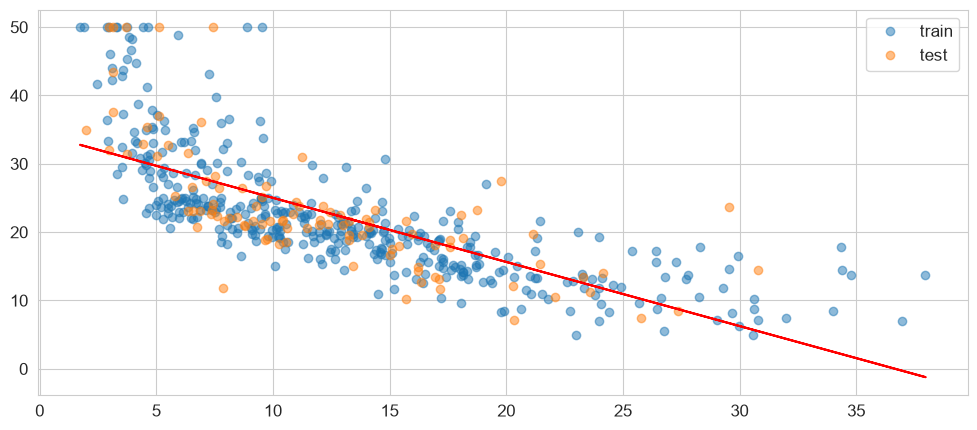

In [15]:
plt.plot(X_train, y_train, "o", alpha=.5, label="train")
plt.plot(X_test, y_test, "o", alpha=.5, label="test")
plt.plot(X_train, lm.predict(X_train), "r")
plt.legend()
plt.show()

Seaborn's `lmplot` draws the same thing straight from a DataFrame: a scatter plot, the fitted line, and a 95% confidence band around it.

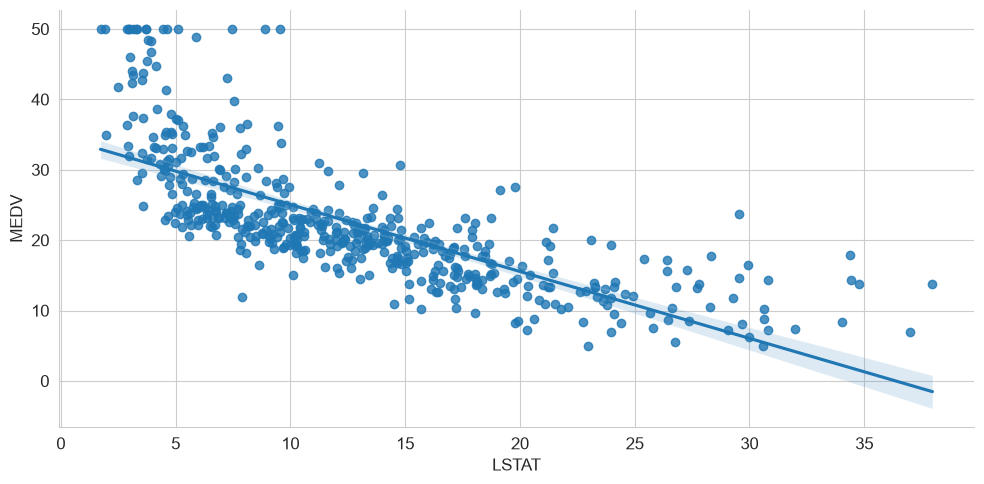

In [16]:
sns.lmplot(x="LSTAT", y="MEDV", data=df_boston, aspect=2)
plt.show()

The points bend away from the straight line. A polynomial of order 2 (section 2.4) follows the curve better:

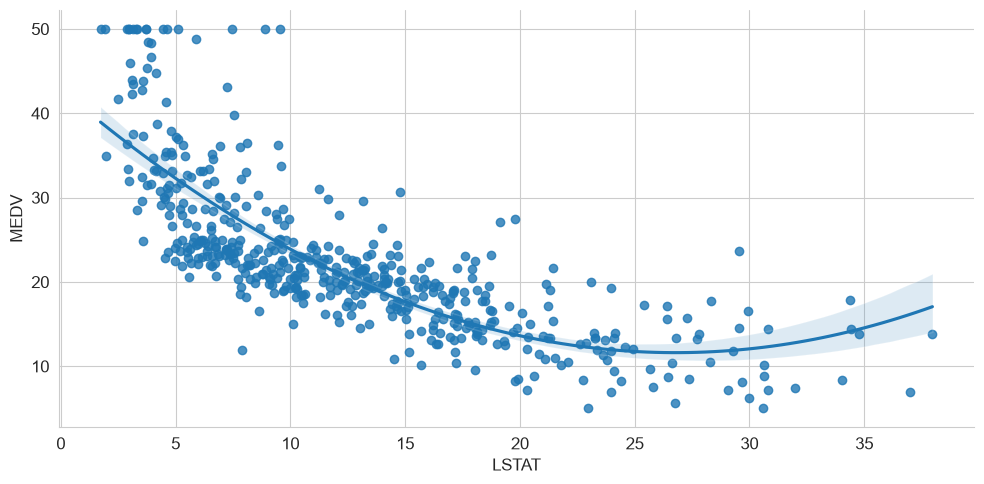

In [17]:
sns.lmplot(x="LSTAT", y="MEDV", data=df_boston, aspect=2, order=2)
plt.show()

## 6. Evaluating a regression

We can evaluate the model fitting by computing the mean squared error ($MSE$) and the coefficient of determination ($R^2$) of the model.

The coefficient $R^2$ is defined as:
$$R^2 = (1 - \textbf{u}/\textbf{v})$$
, where $\textbf{u}$ is the residual sum of squares: $$\textbf{u}=\sum (\textbf{y} - \widehat{\textbf{y}} )^2$$ where ${\textbf{y}}$ is the observed response and $\widehat{\textbf{y}}$ is the predicted response.

And $\textbf{v}$ is the total sum of squares: $$\textbf{v}=\sum (\textbf{y} - \bar{\textbf{y}})^2,$$ where $\bar{\textbf{y}}$ is the mean of the observed data.

The best possible score for $R^2$ is 1.0 (when $\textbf{u}=0$): lower values are worse. $R^2$ is 0.0 when $\textbf{u}=\textbf{v}$.

**With the model's `score` method**, which returns R², and MSE computed by hand:

In [18]:
y_train_pred = lm.predict(X_train)
y_test_pred = lm.predict(X_test)

print('R^2 train:', lm.score(X_train, y_train))
print('R^2 test: ', lm.score(X_test, y_test))

print('MSE train:', np.mean((y_train_pred - y_train)**2))
print('MSE test: ', np.mean((y_test_pred - y_test)**2))

R^2 train: 0.5584660022501389
R^2 test:  0.4825286347804508
MSE train: 37.5327446422984
MSE test:  42.28273844430435


**With `sklearn.metrics`.** MAE and RMSE are in the same units as the target, so they are easier to explain: here, thousands of dollars.

In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print('R^2 test: ', r2_score(y_test, y_test_pred))
print('MSE test: ', mean_squared_error(y_test, y_test_pred))
print('RMSE test:', np.sqrt(mean_squared_error(y_test, y_test_pred)))
print('MAE test: ', mean_absolute_error(y_test, y_test_pred))

R^2 test:  0.4825286347804508
MSE test:  42.28273844430435
RMSE test: 6.5025178542088105
MAE test:  4.509306961929635


Compare the train and test numbers: a model much better on train than on test is overfitting.

**Residual plot.** A residual is the error on one point, $y_i - \hat y_i$. If the model is good, residuals plotted against the predictions look like noise, with no visible pattern.

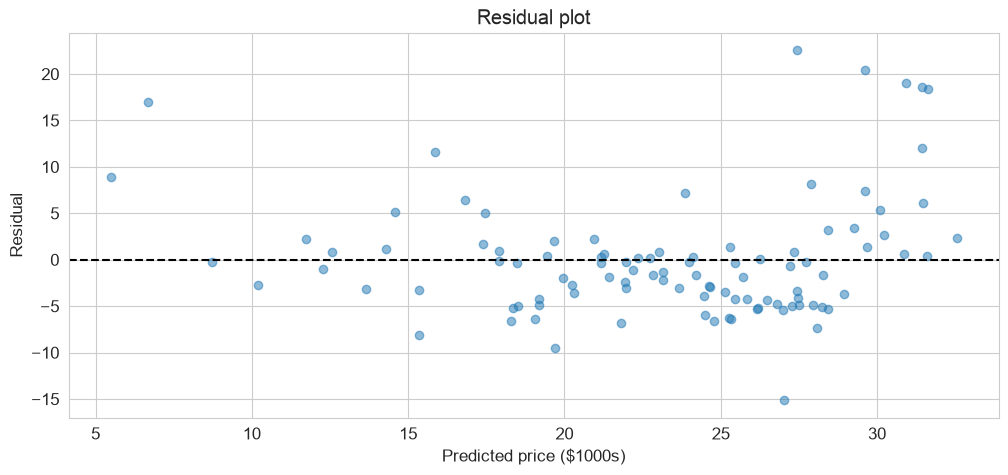

In [20]:
plt.scatter(y_test_pred, y_test - y_test_pred, alpha=0.5)
plt.axhline(0, color='k', linestyle='--')
plt.xlabel('Predicted price ($1000s)')
plt.ylabel('Residual')
plt.title('Residual plot')
plt.show()

This one has a pattern: the big positive residuals sit at both ends, and most residuals in the middle are negative. That is the bend the straight line misses, which the order-2 `lmplot` above already showed.

## 7. Reading a regression summary with statsmodels

scikit-learn is built for prediction. `statsmodels` is built for explanation: its summary tells you whether each coefficient is significant, using the hypothesis tests from Day 2.

`sm.OLS(y, X)` does **not** add an intercept on its own, so we add a column of ones with `sm.add_constant`.

In [21]:
import statsmodels.api as sm

est = sm.OLS(y_train, sm.add_constant(X_train)).fit()
est.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.557
Method:                 Least Squares   F-statistic:                     508.5
Date:                Sun, 04 Oct 2026   Prob (F-statistic):           2.31e-73
Time:                        16:20:16   Log-Likelihood:                -1305.5
No. Observations:                 404   AIC:                             2615.
Df Residuals:                     402   BIC:                             2623.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         34.4041      0.614     56.022      0.000      33.197      35.611
x1            -0.9381      0.042    -22.549      0.000      -1.020      -0.856
==============================================================================
Omnibus:                      111.205   Durbin-Watson:                   2.098
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              229.828
Skew:                           1.464   Prob(JB):                     1.24e-50
Kurtosis:                       5.255   Cond. No.                         29.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

How to read it:

- **coef**: `const` is the intercept and `x1` the slope. They match the scikit-learn model above.
- **P>|t|**: the p-value of a t-test with H₀ "this coefficient is 0". Below 0.05, the feature is a significant predictor.
- **[0.025 0.975]**: the 95% confidence interval for each coefficient.
- **R-squared**: the same R² as before, on the training data.

The **formula API** takes column names straight from a DataFrame and adds the intercept for you. The lab uses it.

In [22]:
import statsmodels.formula.api as smf

model = smf.ols('MEDV ~ LSTAT', data=df_boston).fit()
model.params

Intercept    34.553841
LSTAT        -0.950049
dtype: float64

In [23]:
model.rsquared, model.pvalues['LSTAT']

(np.float64(0.5441462975864797), np.float64(5.081103394388305e-88))

This fit uses every row, not only the training set, so the numbers are close to the ones above but not identical.

## 8. Multiple linear regression

Now we use all 12 features at once.

![](https://miro.medium.com/v2/resize:fit:597/1*RqL8NLlCpcTIzBcsB-3e7A.png)

**how does this look in 4 dimensions? And in 11**

In [24]:
X = df_boston.drop(columns='MEDV')
y = df_boston['MEDV']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape

(404, 12)

In [25]:
lr = LinearRegression()
lr.fit(X_train, y_train)

pd.Series(lr.coef_, index=X.columns).round(3)

CRIM       -0.127
ZN          0.031
INDUS       0.025
CHAS        3.049
NOX       -18.183
RM          4.240
AGE        -0.004
DIS        -1.466
RAD         0.240
TAX        -0.011
PTRATIO    -0.895
LSTAT      -0.538
dtype: float64

In [26]:
r2score_train = lr.score(X_train, y_train)
r2score_test = lr.score(X_test, y_test)

print('R^2 train:', r2score_train)
print('R^2 test: ', r2score_test)
print('MSE test: ', mean_squared_error(y_test, lr.predict(X_test)))

R^2 train: 0.739801993681731
R^2 test:  0.6893967884614722
MSE test:  22.777708563866312


Twelve features explain much more of the price than LSTAT alone. The formula API does the same with `smf.ols('MEDV ~ LSTAT + RM + CRIM', data=df_boston)`.

## 9. Regularization: Ridge and Lasso

With many features, a linear model can chase noise in the training data. Regularization adds a penalty on large coefficients to the error OLS minimises, trading a little training accuracy for a model that generalises better. `alpha` sets how strong the penalty is.

### 9.1 L2 regularization: Ridge

Ridge Regression penalizes the coefficients if they are too far from zero, thus enforcing them to be small in a continuous way. This way, it decreases model complexity while keeping all variables in the model. 

$$ minimize(\sum_{i=0}^n (y_i - \beta_0- \sum_{j=1}^p \beta_jx_{ij})^2 + \alpha\sum_{j=1}^p \beta_j^2) $$
 
where $\beta_j$ are the regression coefficients.


### 9.2 L1 regularization: Lasso

Often, in real problems, there are uninformative variables in the data which prevent proper modeling of the problem and thus, the building of a correct regression model. In such cases, a feature selection process is crucial to select only the informative features and discard non-informative ones. This can be achieved by sparse methods which use a penalization approach, such as *Lasso* (least absolute shrinkage and selection operator) to set some model coefficients to zero (thereby discarding those variables). Sparsity can be seen as an application of Occam’s razor: prefer simpler models to complex ones.

For that, Lasso regression adds a **$\ell_1$-norm** regularization term to the sum of squared errors of prediction (SSE).  Given the set of samples  (𝑋,𝐲) , the objective is to minimize:

$$ minimize(\sum_{i=0}^n (y_i - \beta_0- \sum_{j=1}^p \beta_jx_{ij})^2 + \alpha\sum_{j=1}^p|\beta_j|)$$


**Geometric interpretation**

The left panel shows L1 regularization (lasso regularization) and the right panel L2 regularization (Ridge regression). The ellipses indicate the distribution for no regularization. The shapes (square and circle) show the constraints due to regularization (limiting  $\theta^2$  for ridge regression and $|\theta|$ for Lasso regression). The corners of the L1 regularization create more opportunities for the solution to have zeros for some of the weights.

<center><img src="files/images/regularization-ridge-lasso.png"></center>

More info [here](https://www.datacamp.com/community/tutorials/tutorial-ridge-lasso-elastic-net)

### 9.3 Fitting both

One caveat: the Boston features are on very different scales (TAX is in the hundreds, NOX below 1), so the penalty does not treat them equally and the coefficient sizes are not directly comparable. Scaling features before regularizing is the standard fix; you will meet it in the next lessons.

In [27]:
from sklearn.linear_model import Ridge, Lasso

coefs_lr = pd.Series(np.abs(lr.coef_), X.columns).sort_values()

ridge = Ridge(alpha=1)
ridge.fit(X_train, y_train)
coefs_ridge = pd.Series(np.abs(ridge.coef_), X.columns).sort_values()
r2score_ridge_train = ridge.score(X_train, y_train)
r2score_ridge_test = ridge.score(X_test, y_test)

lasso = Lasso(alpha=1)
lasso.fit(X_train, y_train)
coefs_lasso = pd.Series(np.abs(lasso.coef_), X.columns).sort_values()
r2score_lasso_train = lasso.score(X_train, y_train)
r2score_lasso_test = lasso.score(X_test, y_test)

### 9.4 Comparing the results

Are the coefficients now sparse? Is the score different?

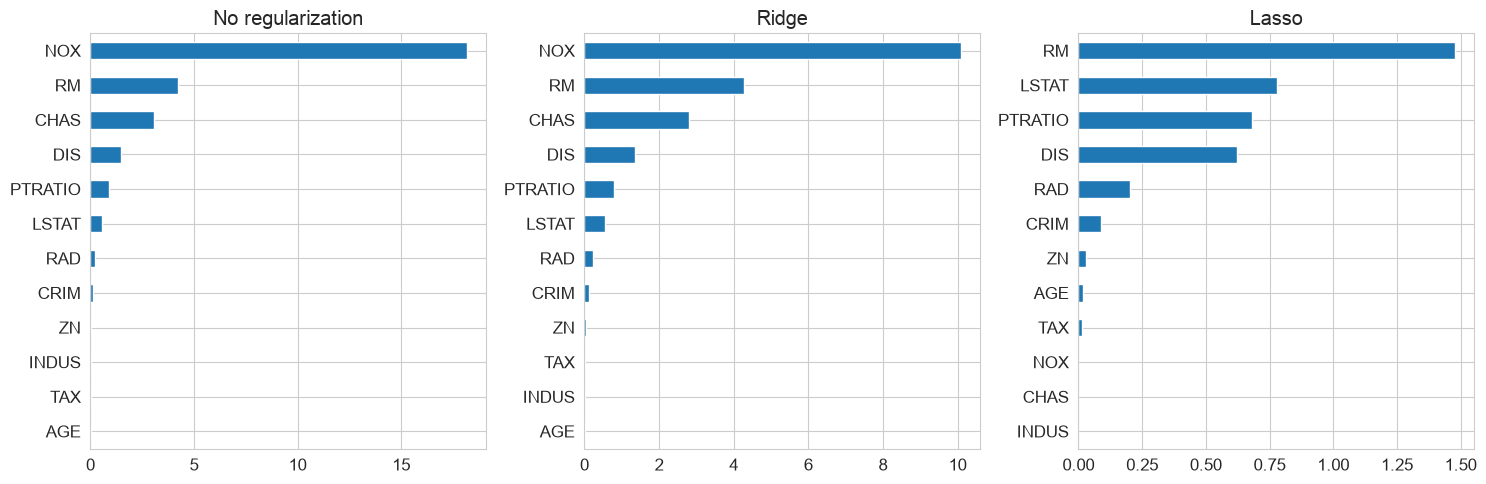

In [28]:
f = plt.figure(figsize=(15, 5))
ax1 = f.add_subplot(131)
ax2 = f.add_subplot(132)
ax3 = f.add_subplot(133)

coefs_lr.plot(kind="barh", title='No regularization', ax=ax1)
coefs_ridge.plot(kind="barh", title='Ridge', ax=ax2)
coefs_lasso.plot(kind="barh", title='Lasso', ax=ax3)
plt.tight_layout()
plt.show()

In [29]:
print('Dropped by Lasso: {}'.format(list(coefs_lasso.index[coefs_lasso == 0])))
print('Largest Lasso coefficient: {}'.format(coefs_lasso.index[-1]))

Dropped by Lasso: ['INDUS', 'CHAS', 'NOX']
Largest Lasso coefficient: RM


In [30]:
scores = [[r2score_train, r2score_test],
          [r2score_ridge_train, r2score_ridge_test],
          [r2score_lasso_train, r2score_lasso_test]]
pd.DataFrame(scores, columns=["Train R^2", "Test R^2"], index=["No regularization", "Ridge", "Lasso"]).round(3)

,Train R^2,Test R^2
No regularization,0.740,0.689
Ridge,0.737,0.686
Lasso,0.683,0.682


- **Ridge** shrinks the coefficients a little and the scores barely move.
- **Lasso** sets three coefficients to exactly zero. It loses some training R², but the test R² stays almost the same: about the same accuracy with 9 features instead of 12.
- NOX is one of the features Lasso drops, even though it had the largest coefficient without regularization. NOX is measured in tiny units, so it needs a large coefficient, and that is exactly what the penalty punishes. This is the scaling caveat from 9.3.

### 9.5 Summary: L1 vs L2

| Aspect              | L1 Regularization (Lasso)                       | L2 Regularization (Ridge)                      |
|---------------------|------------------------------------------------|-----------------------------------------------|
| Penalty             | Sum of absolute values of coefficients          | Sum of squared values of coefficients          |
| Effect on Coefficients | Can shrink some coefficients exactly to zero, performing feature selection | Shrinks coefficients towards zero but rarely zeroes them out |
| Model Complexity    | Produces sparse models with fewer features       | Produces smooth models with small but non-zero coefficients |
| Use Cases           | Useful when you want feature selection            | Useful when all features are relevant but you want to reduce overfitting |
| Impact on Interpretability | Easier to interpret due to feature selection  | Coefficients remain, so model is less sparse but stable |

---

**In practice:**  
- **L1** helps simplify models by selecting important features.  
- **L2** helps improve stability and reduces overfitting without removing features completely.  
- Sometimes, **Elastic Net** combines both penalties for a balanced approach.

## Appendix

Practice and extra material. None of it is taught live.

### A.1 Another estimator: least absolute errors

OLS minimises squared errors. We can minimise other criteria, such as the **sum of absolute errors (SAE)**:

$$
\sum_{j=1}^n |a_0 + a_1 x_j - y_j|
$$

Here is the same six-point example fitted both ways. It reuses `x`, `y`, `a0` and `a1` from section 3.

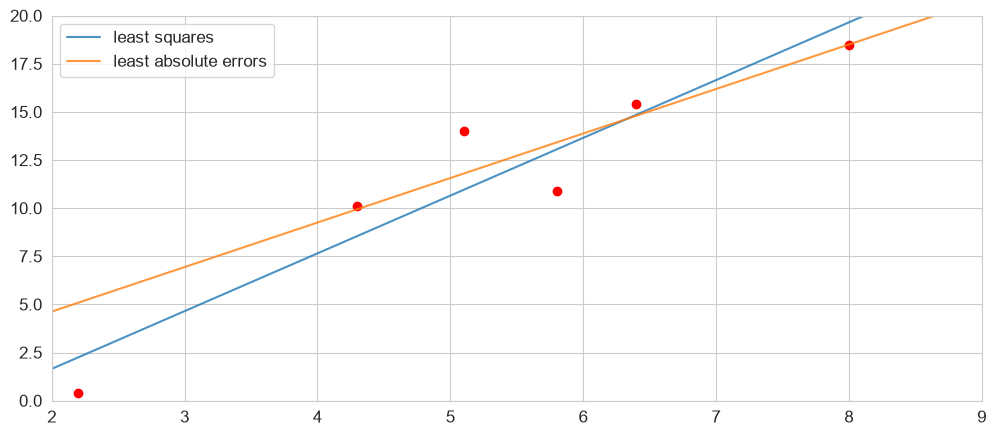

0.0015717044449411344 2.3123174318112456


In [31]:
x = np.array([2.2, 4.3, 5.1, 5.8, 6.4, 8.0])
y = np.array([0.4, 10.1, 14.0, 10.9, 15.4, 18.5])

sae = lambda a, x, y: np.sum(abs(a[0] + a[1]*x - y))
b0, b1 = fmin(sae, [0, 1], args=(x, y), disp=False)

plt.plot(x, y, 'ro')
plt.plot([0, 10], [a0, a0 + a1*10], alpha=0.8, label='least squares')
plt.plot([0, 10], [b0, b0 + b1*10], alpha=0.8, label='least absolute errors')
plt.xlim(2, 9); plt.ylim(0, 20)
plt.legend()
plt.show()
print(b0, b1)

Points far from the line are penalised less, so the absolute-error line is pulled less by the outlying first point.

### A.2 One feature at a time

Which single feature predicts the price best? Fit one simple regression per feature and compare.

In [32]:
scores = []
for feat_name in X_train.columns:
    feat_train = X_train[[feat_name]]
    feat_test = X_test[[feat_name]]

    model_1 = LinearRegression().fit(feat_train, y_train)
    scores.append([feat_name,
                   model_1.score(feat_train, y_train), model_1.score(feat_test, y_test),
                   mean_squared_error(y_train, model_1.predict(feat_train)),
                   mean_squared_error(y_test, model_1.predict(feat_test))])

df_scores = pd.DataFrame(scores, columns=["feature", "train_score", "test_score", "train_mse", "test_mse"]).set_index("feature")
df_scores = df_scores.sort_values(by="test_score", ascending=False)
df_scores

,train_score,test_score,train_mse,test_mse
feature,,,,
LSTAT,0.542318,0.542918,39.760387,33.519549
RM,0.505066,0.370757,42.996616,46.144775
PTRATIO,0.241287,0.318508,65.911961,49.976378
INDUS,0.221414,0.276408,67.638426,53.063745
ZN,0.095792,0.258903,78.551585,54.347454
TAX,0.211411,0.241304,68.507389,55.638030
AGE,0.115747,0.240015,76.818058,55.732582
NOX,0.172863,0.205205,71.856206,58.285326
CRIM,0.144469,0.158721,74.322872,61.694137


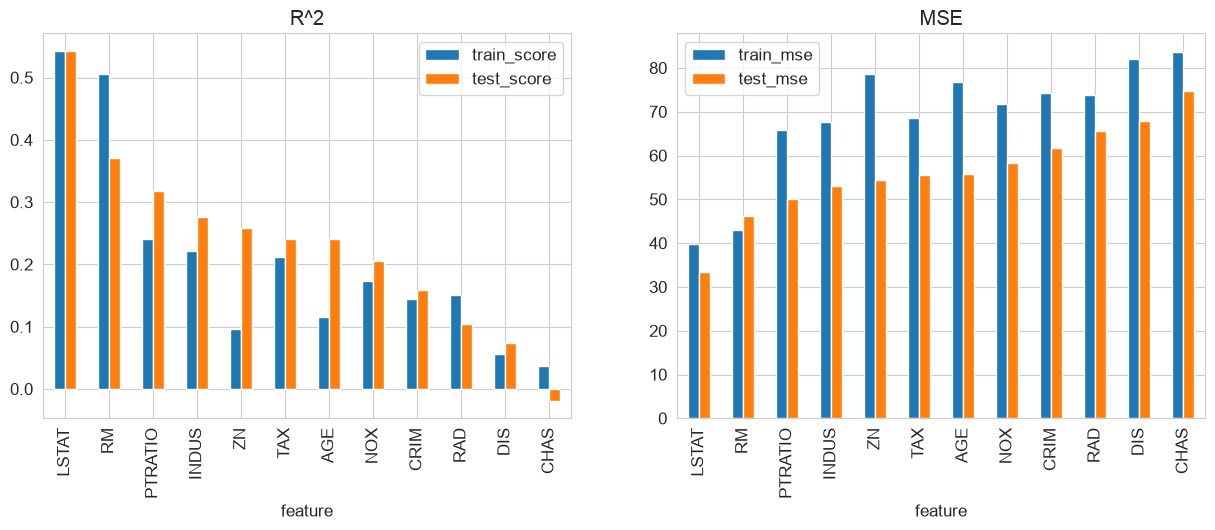

In [33]:
f = plt.figure(figsize=(15, 5))
ax1 = f.add_subplot(121)
ax2 = f.add_subplot(122)

df_scores[["train_score", "test_score"]].plot(kind="bar", ax=ax1, title='R^2')
df_scores[["train_mse", "test_mse"]].plot(kind="bar", ax=ax2, title='MSE')
plt.show()

### A.3 Exploring relationships before modelling

**The importance of plotting.**

Anscombe's quartet comprises four data sets that have nearly identical simple descriptive statistics, yet have very different distributions and appear very different when graphed. Each dataset consists of eleven (x,y) points. They were constructed in 1973 by the statistician Francis Anscombe to demonstrate both the importance of graphing data before analyzing it and the effect of outliers and other influential observations on statistical properties.

<center><img src="files/images/Anscombe's_quartet_3.svg"  width="600"></center>

Source [Wikipedia](https://en.wikipedia.org/wiki/Anscombe%27s_quartet).

We can also use corr function from Pandas and heatmap function from Seaborn for studying the variables relationship, plotting a diagonal correlation matrix.

The correlation coefficient ranges from -1 to 1. If the value is close to 1, it means that there is a strong positive correlation between the two variables. When it is close to -1, the variables have a strong negative correlation.

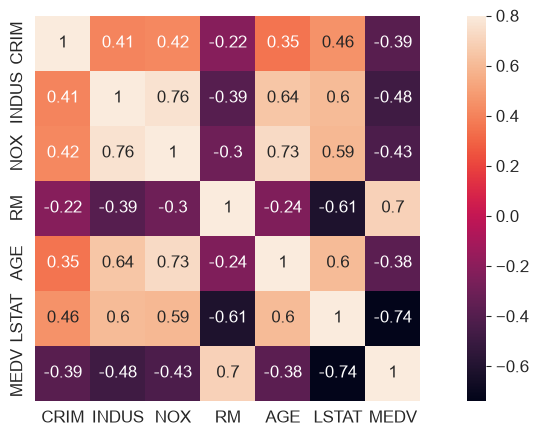

In [34]:
corrmat = df_boston[['CRIM', 'INDUS', 'NOX', 'RM', 'AGE', 'LSTAT', 'MEDV']].corr()
sns.heatmap(corrmat, vmax=.8, square=True, annot=True)
plt.show()

Let's explore multiple variables relationships using a scatter plot matrix. The scatter plot is a grid of plots of multiple varaibles one against the other, showing the pairwise relationship of each variable to the others.

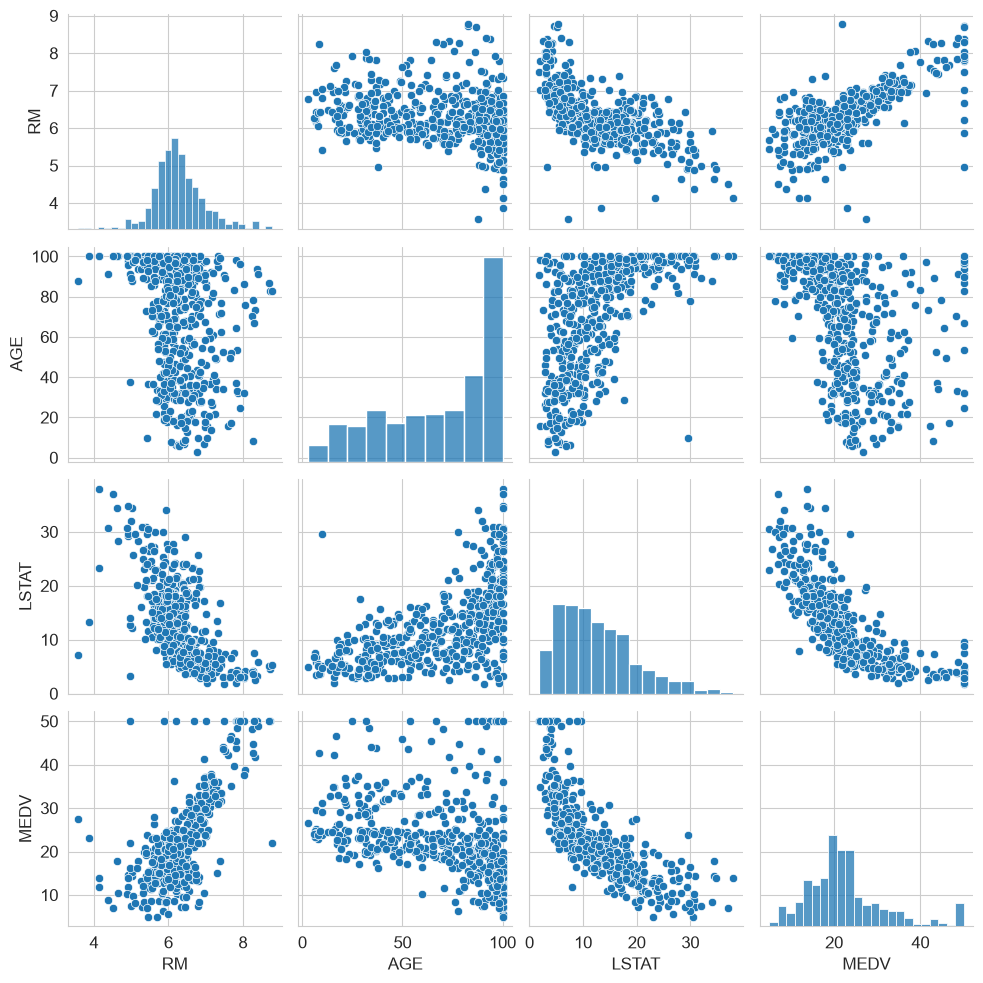

In [35]:
sns.pairplot(df_boston[['RM', 'AGE', 'LSTAT', 'MEDV']])
plt.show()

We can visually analyze the pairwise relationships in the scatter plots. The diagonal axe contains a plot to show the univariate distribution of the data for the variable in that column.